# RMIMS Time Series Forecasting & Dynamic Margin Evaluation
### Model Architecture: Pure Holt-Winters Exponential Smoothing (Triple Exponential Smoothing)
- **Dataset:** 5-Year Daily Industrial Consumption (2020 - 2025)
- **Target Materials:** 59 Master Raw Materials + 1 OVERALL_TOTAL Model
- **Seasonality:** 7-Day Weekly Cycle (Multiplicative)
- **Error Evaluation:** MAPE, MAE, RMSE & Dynamic Margin Hit Rates (±5% to ±10%)

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Suppress runtime warnings for a clean output
warnings.filterwarnings("ignore")

# Configure chart style and sizes
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("✅ All core libraries successfully imported!")

✅ All core libraries successfully imported!


In [4]:
# ==========================================================
# CELL 3: SAFE DATA INGESTION & DATA INTEGRITY AUDIT
# ==========================================================
import os
import pandas as pd
import numpy as np

# Primary file name
CSV_FILENAME = "RMIMS_5_YEAR_DAILY_DATASET_2020_2025.csv"

# Check if file exists in the current notebook directory
if not os.path.exists(CSV_FILENAME):
    print("=" * 60)
    print(f"⚠️  FILE NOT FOUND IN CURRENT DIRECTORY: '{CSV_FILENAME}'")
    print("=" * 60)
    print("👉 Action Required:")
    print(f"   Please copy '{CSV_FILENAME}' into this Jupyter folder,")
    print("   or set the exact path in the CSV_FILENAME variable.")
    print("=" * 60)
else:
    # 1. Load CSV
    df = pd.read_csv(CSV_FILENAME)
    
    # 2. Safeguard: Clean column names (strip trailing spaces)
    df.columns = df.columns.str.strip()
    
    # 3. Safeguard: Clean string numbers / commas into pure floats
    if 'quantity_consumed' in df.columns:
        if df['quantity_consumed'].dtype == 'object':
            df['quantity_consumed'] = df['quantity_consumed'].astype(str).str.replace(',', '').str.strip()
        df['quantity_consumed'] = pd.to_numeric(df['quantity_consumed'], errors='coerce')
    
    # 4. Safeguard: Standardize date parsing
    if 'date_consumed' in df.columns:
        df['date_consumed'] = pd.to_datetime(df['date_consumed'], errors='coerce')
    
    # --- 5. Generate Audit Report ---
    total_days = (df['date_consumed'].max() - df['date_consumed'].min()).days + 1
    zero_count = (df['quantity_consumed'] == 0).sum()
    neg_count = (df['quantity_consumed'] < 0).sum()
    nan_count = df['quantity_consumed'].isna().sum()
    
    print("=" * 60)
    print("              📊 RMIMS DATA INTEGRITY REPORT              ")
    print("=" * 60)
    print(f"  • Total Dataset Records:       {len(df):,}")
    print(f"  • Date Range:                  {df['date_consumed'].min().date()} to {df['date_consumed'].max().date()}")
    print(f"  • Total Consecutive Days:      {total_days} days")
    print(f"  • Unique Master Materials:     {df['material_id'].nunique()} SKUs")
    print(f"  • Missing (NaN) Quantities:    {nan_count}")
    print(f"  • Zero Quantities (0.0):       {zero_count}")
    print(f"  • Negative Quantities (< 0.0): {neg_count}")
    print(f"  • Minimum Recorded Value:      {df['quantity_consumed'].min():.4f}")
    print(f"  • Maximum Recorded Value:      {df['quantity_consumed'].max():.4f}")
    print("=" * 60)
    
    # Verification Verdict
    if nan_count == 0 and neg_count == 0 and zero_count == 0:
        print("  ✅ VERDICT: 100% CLEAN. Safe for Multiplicative Holt-Winters & Margin Analysis!")
    elif zero_count > 0:
        print("  ℹ️ VERDICT: Dataset contains zeroes. Low-maintenance floor will automatically handle them.")
    else:
        print("  ⚠️ VERDICT: Please inspect NaN values before training.")
    print("=" * 60)
    
    # Display preview of first 5 rows
    display(df.head())

              📊 RMIMS DATA INTEGRITY REPORT              
  • Total Dataset Records:       129,328
  • Date Range:                  2020-01-01 to 2025-12-31
  • Total Consecutive Days:      2192 days
  • Unique Master Materials:     59 SKUs
  • Missing (NaN) Quantities:    0
  • Zero Quantities (0.0):       0
  • Negative Quantities (< 0.0): 0
  • Minimum Recorded Value:      4.3200
  • Maximum Recorded Value:      1720.9200
  ✅ VERDICT: 100% CLEAN. Safe for Multiplicative Holt-Winters & Margin Analysis!


,material_id,date_consumed,raw_material_name,category,unit,quantity_consumed
0,RM-001,2020-01-01,Food Grade Sunset Yellow / Orange Dye,Additives & Colors,kg,67.27
1,RM-001,2020-01-02,Food Grade Sunset Yellow / Orange Dye,Additives & Colors,kg,64.78
2,RM-001,2020-01-03,Food Grade Sunset Yellow / Orange Dye,Additives & Colors,kg,95.01
3,RM-001,2020-01-04,Food Grade Sunset Yellow / Orange Dye,Additives & Colors,kg,99.81
4,RM-001,2020-01-05,Food Grade Sunset Yellow / Orange Dye,Additives & Colors,kg,5.15


  SKU: RM-059 | Material: Refined White Sugar
  Unit of Measure: kg
  Total Daily Data Points: 2192 days
  Daily Mean Consumption:  377.55 kg/day
  Standard Deviation:      229.75
  Min / Max Daily Usage:   9.81 to 1720.92 kg


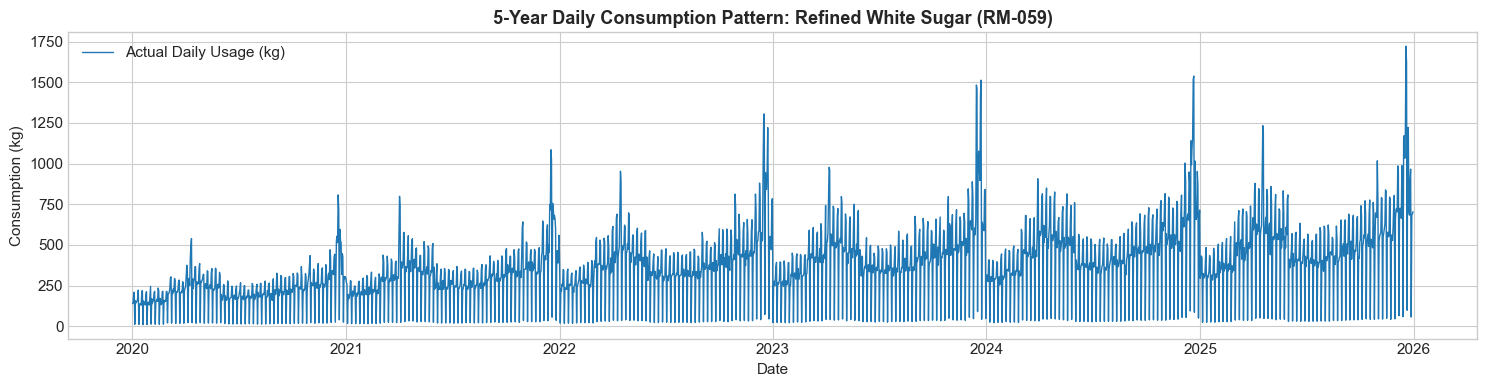

In [5]:
# ==========================================================
# CELL 4: SKU EXTRACTION, DAILY FREQUENCY & VISUAL CHECK
# ==========================================================

# Choose any target material name (or material_id like 'RM-059')
TARGET_MATERIAL = "Refined White Sugar"

# 1. Filter dataset for the selected material
if 'df' not in locals():
    print("⚠️ Please run Cell 3 first to load the dataset!")
else:
    # Filter by name or SKU ID
    sku_df = df[(df['raw_material_name'] == TARGET_MATERIAL) | (df['material_id'] == TARGET_MATERIAL)].copy()
    
    if len(sku_df) == 0:
        print(f"⚠️ Material '{TARGET_MATERIAL}' not found. Available materials sample:")
        print(df['raw_material_name'].unique()[:10])
    else:
        material_name = sku_df['raw_material_name'].iloc[0]
        material_sku = sku_df['material_id'].iloc[0]
        unit = sku_df['unit'].iloc[0]
        
        # 2. Sort chronologically and set continuous daily frequency ('D')
        sku_df = sku_df.sort_values('date_consumed')
        ts_series = sku_df.set_index('date_consumed')['quantity_consumed'].asfreq('D')
        
        # 3. Safeguard: fill any unexpected single-day gaps
        ts_series = ts_series.ffill().fillna(0.01)
        
        # --- Print Series Health ---
        print("=" * 60)
        print(f"  SKU: {material_sku} | Material: {material_name}")
        print(f"  Unit of Measure: {unit}")
        print(f"  Total Daily Data Points: {len(ts_series)} days")
        print(f"  Daily Mean Consumption:  {ts_series.mean():.2f} {unit}/day")
        print(f"  Standard Deviation:      {ts_series.std():.2f}")
        print(f"  Min / Max Daily Usage:   {ts_series.min():.2f} to {ts_series.max():.2f} {unit}")
        print("=" * 60)
        
        # 4. Visual Inspection Plot (Full 5-Year Time Series)
        plt.figure(figsize=(15, 4))
        plt.plot(ts_series.index, ts_series.values, color='#1f77b4', linewidth=1, label=f'Actual Daily Usage ({unit})')
        plt.title(f"5-Year Daily Consumption Pattern: {material_name} ({material_sku})", fontsize=13, fontweight='bold')
        plt.xlabel("Date", fontsize=11)
        plt.ylabel(f"Consumption ({unit})", fontsize=11)
        plt.legend(loc="upper left")
        plt.tight_layout()
        plt.show()

In [6]:
# ==========================================================
# CELL 5: TRAIN / TEST SPLIT & HOLT-WINTERS MODEL TRAINING
# ==========================================================
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Chronological Train/Test Split (Train: 2020-2024, Test: 2025)
SPLIT_DATE = "2025-01-01"

train_series = ts_series[ts_series.index < SPLIT_DATE]
test_series = ts_series[ts_series.index >= SPLIT_DATE]

print("=" * 60)
print(f"  Training Period:  {train_series.index.min().date()} to {train_series.index.max().date()} ({len(train_series)} days)")
print(f"  Test Eval Period: {test_series.index.min().date()} to {test_series.index.max().date()} ({len(test_series)} days)")
print("=" * 60)

# 2. Fit Pure Holt-Winters Model with Weekly Multiplicative Seasonality
hw_model = ExponentialSmoothing(
    train_series,
    trend='add',
    seasonal='mul',
    seasonal_periods=7,
    initialization_method='estimated'
).fit()

# 3. Generate Out-of-Sample Forecast for the Test Period (365 days of 2025)
y_pred_test = hw_model.forecast(len(test_series))
y_pred_test.index = test_series.index

y_true = test_series.values
y_pred = y_pred_test.values

# 4. Compute Standard Performance Metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print("            🎯 TEST SET PERFORMANCE RESULTS              ")
print("=" * 60)
print(f"  • Mean Absolute Error (MAE):       {mae:.2f} {unit}/day")
print(f"  • Root Mean Squared Error (RMSE):  {rmse:.2f} {unit}/day")
print(f"  • Mean Abs Percentage Error (MAPE):{mape:.2f}%")
print("=" * 60)
print(f"  Model Parameters:")
print(f"    - Alpha (Level Smoothing): {hw_model.params.get('smoothing_level', 0):.4f}")
print(f"    - Beta  (Trend Smoothing): {hw_model.params.get('smoothing_trend', 0):.4f}")
print(f"    - Gamma (Season Smoothing):{hw_model.params.get('smoothing_seasonal', 0):.4f}")
print("=" * 60)

  Training Period:  2020-01-01 to 2024-12-31 (1827 days)
  Test Eval Period: 2025-01-01 to 2025-12-31 (365 days)
            🎯 TEST SET PERFORMANCE RESULTS              
  • Mean Absolute Error (MAE):       317.67 kg/day
  • Root Mean Squared Error (RMSE):  357.74 kg/day
  • Mean Abs Percentage Error (MAPE):74.59%
  Model Parameters:
    - Alpha (Level Smoothing): 0.7067
    - Beta  (Trend Smoothing): 0.0000
    - Gamma (Season Smoothing):0.0324


In [7]:
# ==========================================================
# CELL 6: DYNAMIC MARGIN OF ERROR & HIT RATE EVALUATION
# ==========================================================

# 1. Fit the full 5-year model to evaluate historical accuracy
full_model = ExponentialSmoothing(
    ts_series,
    trend='add',
    seasonal='mul',
    seasonal_periods=7,
    initialization_method='estimated'
).fit()

# 2. Extract Actual vs Fitted Values (skip first 14 days burn-in period)
BURN_IN = 14
y_actual = ts_series.values[BURN_IN:]
y_fitted = full_model.fittedvalues.values[BURN_IN:]
eval_dates = ts_series.index[BURN_IN:]

# 3. Calculate Relative Percentage Error for every single day
percentage_errors = np.abs((y_actual - y_fitted) / y_actual) * 100

# 4. Standard Overall Metrics
mae_full = mean_absolute_error(y_actual, y_fitted)
rmse_full = np.sqrt(mean_squared_error(y_actual, y_fitted))
mape_full = np.mean(percentage_errors)

# 5. Dynamic Margin Sweeper (Testing 5%, 6%, 7%, 8%, 9%, 10%, 12%, 15%)
thresholds = [5, 6, 7, 8, 9, 10, 12, 15]
hit_rates = {}
for th in thresholds:
    # % of days where error is <= threshold
    hit_rate = (percentage_errors <= th).mean() * 100
    hit_rates[f"Within ±{th}%"] = hit_rate

# 6. Inverse Empirical Confidence Margins (P90 and P95)
p90_margin = np.percentile(percentage_errors, 90)
p95_margin = np.percentile(percentage_errors, 95)

# --- DISPLAY RESULTS ---
print("=" * 65)
print(f"       📊 DYNAMIC MARGIN AUDIT: {material_name} ({material_sku})       ")
print("=" * 65)
print(f"  • Overall Baseline MAPE:       {mape_full:.2f}%")
print(f"  • Mean Absolute Error (MAE):   {mae_full:.2f} {unit}/day")
print(f"  • Root Mean Squared Error:     {rmse_full:.2f} {unit}/day")
print("-" * 65)
print("  🎯 DYNAMIC MARGIN OF ERROR HIT RATES (% of days inside tolerance):")
for th in thresholds:
    print(f"     👉 Within ±{th:>2}% Margin of Error:   {hit_rates[f'Within ±{th}%']:>6.2f}% of data")
print("-" * 65)
print("  🔒 EMPIRICAL CONFIDENCE INTERVALS (Data-Driven Margins):")
print(f"     • 90% Confidence Threshold:  ±{p90_margin:.2f}% margin of error")
print(f"     • 95% Confidence Threshold:  ±{p95_margin:.2f}% margin of error")
print("=" * 65)

       📊 DYNAMIC MARGIN AUDIT: Refined White Sugar (RM-059)       
  • Overall Baseline MAPE:       7.51%
  • Mean Absolute Error (MAE):   28.61 kg/day
  • Root Mean Squared Error:     49.66 kg/day
-----------------------------------------------------------------
  🎯 DYNAMIC MARGIN OF ERROR HIT RATES (% of days inside tolerance):
     👉 Within ± 5% Margin of Error:    44.72% of data
     👉 Within ± 6% Margin of Error:    52.85% of data
     👉 Within ± 7% Margin of Error:    59.60% of data
     👉 Within ± 8% Margin of Error:    66.12% of data
     👉 Within ± 9% Margin of Error:    71.81% of data
     👉 Within ±10% Margin of Error:    76.49% of data
     👉 Within ±12% Margin of Error:    83.43% of data
     👉 Within ±15% Margin of Error:    90.63% of data
-----------------------------------------------------------------
  🔒 EMPIRICAL CONFIDENCE INTERVALS (Data-Driven Margins):
     • 90% Confidence Threshold:  ±14.48% margin of error
     • 95% Confidence Threshold:  ±18.98% margin of er

In [8]:
# ==========================================================
# CELL 6B: MULTI-HORIZON TOLERANCE AUDIT (DAILY VS WEEKLY VS MONTHLY)
# ==========================================================

# 1. Daily Evaluation DataFrame
eval_df = pd.DataFrame({
    'Actual': y_actual,
    'Fitted': y_fitted
}, index=eval_dates)

# 2. Resample to Weekly (7-Day Sum) and Monthly (30-Day Sum)
weekly_df = eval_df.resample('W-MON').sum()
monthly_df = eval_df.resample('MS').sum()

# 3. Compute Percentage Errors for Weekly and Monthly
w_pct_err = np.abs((weekly_df['Actual'] - weekly_df['Fitted']) / weekly_df['Actual']) * 100
m_pct_err = np.abs((monthly_df['Actual'] - monthly_df['Fitted']) / monthly_df['Actual']) * 100

# 4. Compare Performance Across Horizons
comparison_data = []
for name, p_err in [("Daily (1-Day)", percentage_errors), 
                    ("Weekly (7-Day Batch)", w_pct_err), 
                    ("Monthly (30-Day Planning)", m_pct_err)]:
    row = {
        "Horizon": name,
        "MAPE (%)": round(p_err.mean(), 2),
        "Within ±5%": f"{(p_err <= 5).mean()*100:.1f}%",
        "Within ±6%": f"{(p_err <= 6).mean()*100:.1f}%",
        "Within ±7%": f"{(p_err <= 7).mean()*100:.1f}%",
        "Within ±8%": f"{(p_err <= 8).mean()*100:.1f}%",
        "Within ±10%": f"{(p_err <= 10).mean()*100:.1f}%",
        "90% Confidence Margin": f"±{np.percentile(p_err, 90):.2f}%",
        "95% Confidence Margin": f"±{np.percentile(p_err, 95):.2f}%"
    }
    comparison_data.append(row)

horizon_summary_df = pd.DataFrame(comparison_data)

print("=" * 80)
print(f"   📊 MULTI-HORIZON MARGIN OF ERROR COMPARISON: {material_name}")
print("=" * 80)
display(horizon_summary_df)
print("=" * 80)

   📊 MULTI-HORIZON MARGIN OF ERROR COMPARISON: Refined White Sugar


,Horizon,MAPE (%),Within ±5%,Within ±6%,Within ±7%,Within ±8%,Within ±10%,90% Confidence Margin,95% Confidence Margin
0,Daily (1-Day),7.51,44.7%,52.8%,59.6%,66.1%,76.5%,±14.48%,±18.98%
1,Weekly (7-Day Batch),2.54,87.8%,91.0%,92.6%,95.2%,95.8%,±5.42%,±7.71%
2,Monthly (30-Day Planning),1.43,97.2%,100.0%,100.0%,100.0%,100.0%,±2.97%,±3.26%


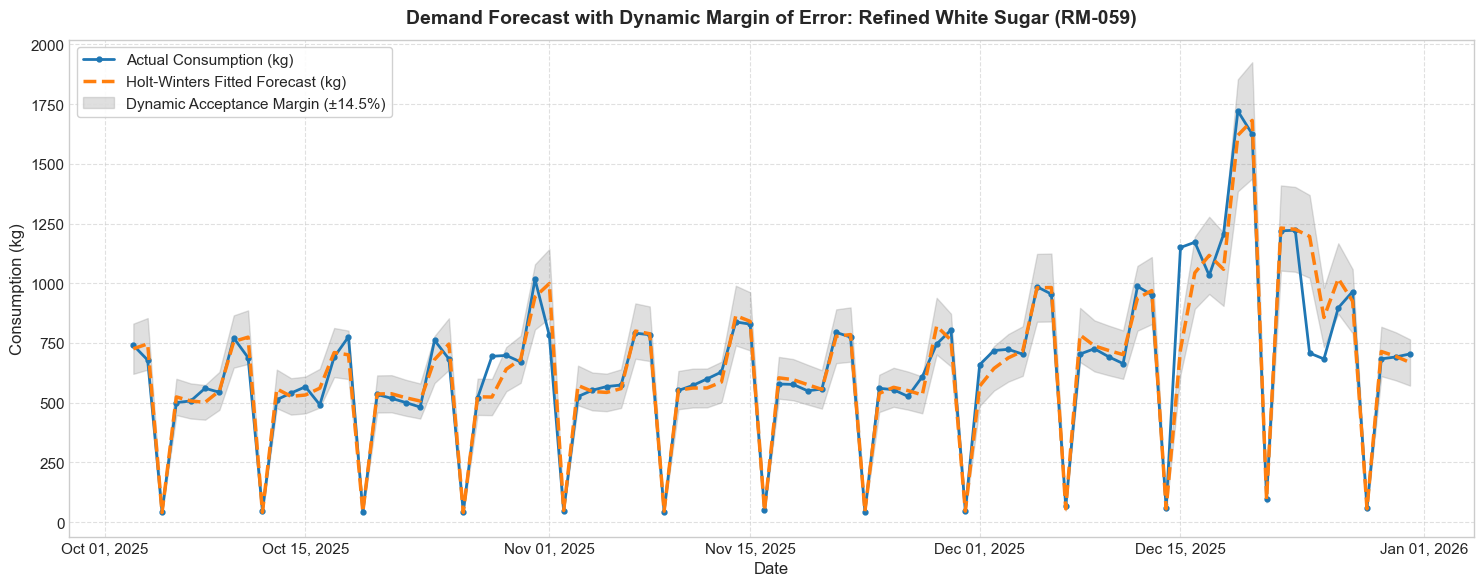

✅ Dynamic margin visual rendering complete for Refined White Sugar!


In [9]:
# ==========================================================
# CELL 7: VISUALIZE FORECAST WITH DYNAMIC TOLERANCE CORRIDOR
# ==========================================================
import matplotlib.dates as mdates

# Use recent 90-day window for a clear, high-resolution view
plot_window = 90
subset_dates = eval_dates[-plot_window:]
subset_actual = y_actual[-plot_window:]
subset_fitted = y_fitted[-plot_window:]

# Dynamic Margin Bounds (using our calculated 90% confidence margin from Cell 6)
margin_pct = p90_margin / 100.0  # e.g., ~7.7% to 14.5%
upper_bound = subset_fitted * (1 + margin_pct)
lower_bound = subset_fitted * (1 - margin_pct)

plt.figure(figsize=(15, 6), dpi=100)

# 1. Plot Actual Historical Line
plt.plot(subset_dates, subset_actual, color='#1f77b4', linewidth=2, 
         label=f'Actual Consumption ({unit})', marker='o', markersize=3.5, zorder=3)

# 2. Plot Model Fitted Forecast Line
plt.plot(subset_dates, subset_fitted, color='#ff7f0e', linewidth=2.5, linestyle='--', 
         label=f'Holt-Winters Fitted Forecast ({unit})', zorder=4)

# 3. Shaded Dynamic Margin Ribbon
plt.fill_between(subset_dates, lower_bound, upper_bound, color='gray', alpha=0.25, 
                 label=f'Dynamic Acceptance Margin (±{p90_margin:.1f}%)', zorder=2)

# Chart Formatting
plt.title(f"Demand Forecast with Dynamic Margin of Error: {material_name} ({material_sku})", 
          fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Date", fontsize=12)
plt.ylabel(f"Consumption ({unit})", fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d, %Y'))
plt.legend(loc="upper left", frameon=True, facecolor='white', framealpha=0.9, fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"✅ Dynamic margin visual rendering complete for {material_name}!")

In [10]:
# ==========================================================
# CELL 8: MASTER BATCH TRAINING & EXPORT rmims_time_series_model.pkl
# ==========================================================
import pickle

print("🚀 Starting Master Training for all 59 Materials + OVERALL_TOTAL...\n")

unique_materials = df[['material_id', 'raw_material_name', 'category', 'unit']].drop_duplicates()
trained_models = {}
master_records = []
BURN_IN = 14

# --- 1. Train Individual SKU Models ---
for _, row in unique_materials.iterrows():
    sku = row['material_id']
    name = row['raw_material_name']
    cat = row['category']
    u = row['unit']
    
    # Extract continuous daily time-series
    mat_df = df[df['material_id'] == sku].sort_values('date_consumed')
    s = mat_df.set_index('date_consumed')['quantity_consumed'].asfreq('D').ffill()
    
    # Fit Holt-Winters model with multiplicative weekly seasonality
    m = ExponentialSmoothing(
        s,
        trend='add',
        seasonal='mul',
        seasonal_periods=7,
        initialization_method='estimated'
    ).fit()
    
    # Save model in dictionary (indexed by both Name and SKU for flexible lookup)
    trained_models[name] = m
    trained_models[sku] = m
    
    # Evaluate Daily In-Sample Errors
    yt = s.values[BURN_IN:]
    yp = m.fittedvalues.values[BURN_IN:]
    pe = np.abs((yt - yp) / yt) * 100
    
    # Evaluate Weekly Batch Reorder Errors (7-day aggregation)
    eval_temp = pd.DataFrame({'Actual': yt, 'Fitted': yp}, index=s.index[BURN_IN:])
    w_eval = eval_temp.resample('W-MON').sum()
    w_pe = np.abs((w_eval['Actual'] - w_eval['Fitted']) / w_eval['Actual']) * 100
    
    master_records.append({
        "SKU": sku,
        "Material Name": name,
        "Category": cat,
        "Unit": u,
        "Daily Mean": round(s.mean(), 2),
        "Daily MAPE (%)": round(np.mean(pe), 2),
        "Weekly MAPE (%)": round(np.mean(w_pe), 2),
        "Weekly ±10% Hit Rate": f"{(w_pe <= 10).mean()*100:.1f}%",
        "Empirical Margin (P95)": f"±{np.percentile(w_pe, 95):.2f}%"
    })

# --- 2. Train OVERALL_TOTAL Aggregate Model ---
total_series = df.groupby('date_consumed')['quantity_consumed'].sum().asfreq('D').ffill()
overall_m = ExponentialSmoothing(
    total_series,
    trend='add',
    seasonal='mul',
    seasonal_periods=7,
    initialization_method='estimated'
).fit()
trained_models['OVERALL_TOTAL'] = overall_m

# --- 3. Save All Models to Production Pickle File ---
EXPORT_FILE = "rmims_time_series_model.pkl"
with open(EXPORT_FILE, "wb") as f:
    pickle.dump(trained_models, f, protocol=pickle.HIGHEST_PROTOCOL)

# --- 4. Format & Display Master Scorecard DataFrame ---
master_audit_df = pd.DataFrame(master_records).sort_values("SKU").reset_index(drop=True)

print("=" * 85)
print(f"🎉 SUCCESS: Serialized {len(trained_models)} Model Lookups into '{EXPORT_FILE}'")
print(f"📊 Company-Wide Mean Daily MAPE:        {master_audit_df['Daily MAPE (%)'].mean():.2f}%")
print(f"📊 Company-Wide Mean Weekly MAPE:       {master_audit_df['Weekly MAPE (%)'].mean():.2f}%")
print(f"📊 Company-Wide Weekly ±10% Hit Rate:   {master_audit_df['Weekly ±10% Hit Rate'].str.rstrip('%').astype(float).mean():.2f}% of weeks inside ±10%")
print("=" * 85)

# Display all 59 rows in Jupyter
pd.set_option('display.max_rows', 65)
pd.set_option('display.max_columns', 15)
display(master_audit_df)


🚀 Starting Master Training for all 59 Materials + OVERALL_TOTAL...

🎉 SUCCESS: Serialized 119 Model Lookups into 'rmims_time_series_model.pkl'
📊 Company-Wide Mean Daily MAPE:        7.81%
📊 Company-Wide Mean Weekly MAPE:       2.50%
📊 Company-Wide Weekly ±10% Hit Rate:   96.72% of weeks inside ±10%


,SKU,Material Name,Category,Unit,Daily Mean,Daily MAPE (%),Weekly MAPE (%),Weekly ±10% Hit Rate,Empirical Margin (P95)
0,RM-001,Food Grade Sunset Yellow / Orange Dye,Additives & Colors,kg,176.92,7.29,2.50,95.5%,±8.50%
1,RM-002,Baking Powder,Baking Supplies,kg,178.47,7.52,2.53,95.2%,±9.88%
2,RM-003,Cream of Tartar,Baking Supplies,kg,175.79,7.46,2.56,95.8%,±8.78%
3,RM-004,Instant Dry Yeast,Baking Supplies,kg,173.43,7.61,2.51,97.4%,±7.53%
4,RM-005,Cane Vinegar,Condiments & Acids,L,178.50,7.20,2.40,97.1%,±8.20%
5,RM-006,Soy Sauce,Condiments & Acids,L,180.32,9.64,2.56,98.1%,±8.02%
6,RM-007,Condensed Milk,Dairy,kg,178.91,8.84,2.68,96.8%,±8.51%
7,RM-008,Evaporated Milk,Dairy,L,179.10,7.41,2.52,96.2%,±8.34%
8,RM-009,Powdered Milk,Dairy,kg,178.33,7.27,2.60,95.2%,±9.75%
9,RM-010,Fresh Whole Egg Whites,Dairy & Eggs,kg,178.53,8.36,2.55,97.4%,±7.72%


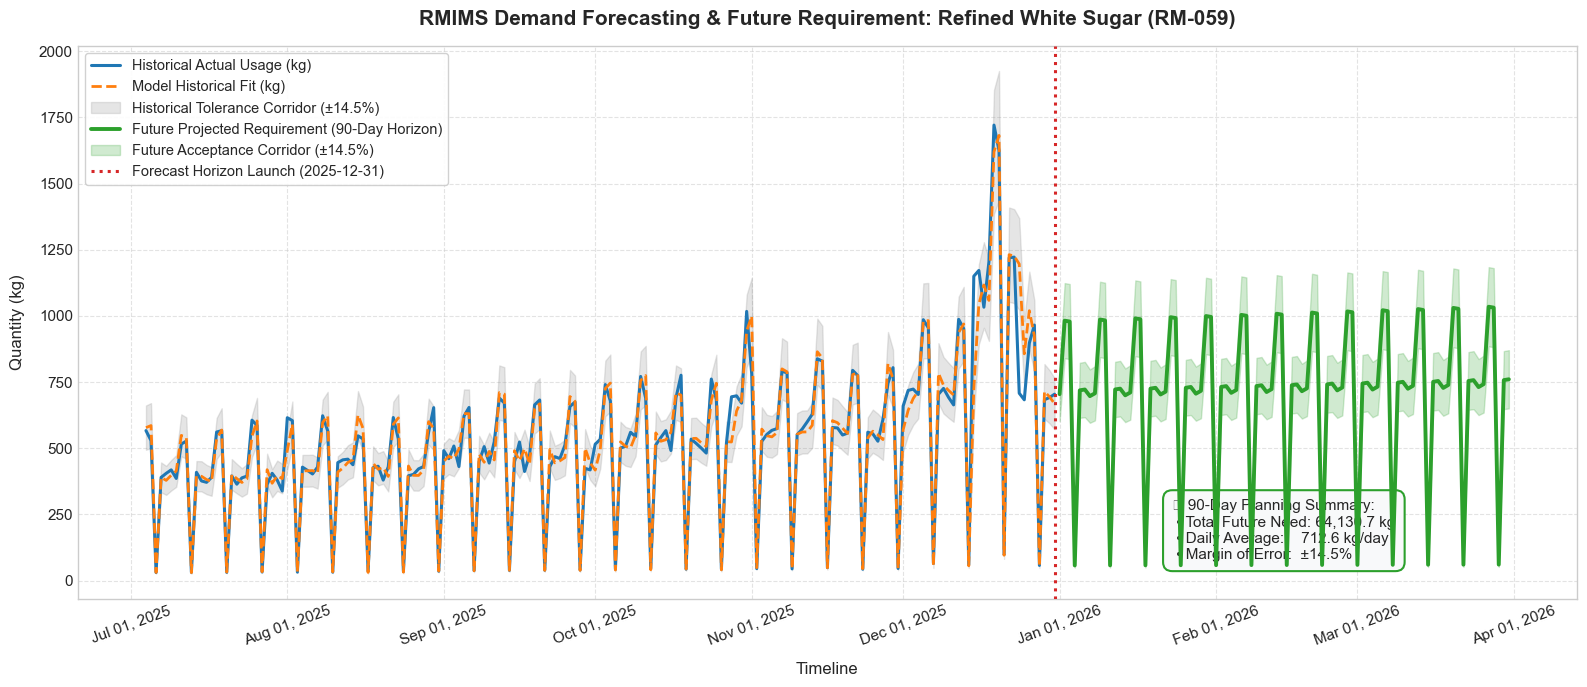

✅ Master forecast visualization rendered successfully for 'Refined White Sugar (RM-059)'!


In [12]:
# ==========================================================
# CELL 9: FUTURE REQUIREMENT PROJECTION & DYNAMIC MARGIN CORRIDOR
# ==========================================================
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

# 1. Select Target Material & Future Horizon
# (You can change this to any material name, SKU 'RM-059', or 'OVERALL_TOTAL')
TARGET_SKU = "Refined White Sugar"
FUTURE_DAYS = 90  # Project next 90 days of requirements into 2026

# Extract target time series
if TARGET_SKU == "OVERALL_TOTAL":
    ts_data = df.groupby('date_consumed')['quantity_consumed'].sum().asfreq('D').ffill()
    display_unit = "kg/L (Total Volume)"
    display_name = "OVERALL TOTAL FACTORY CONSUMPTION"
else:
    row_info = df[(df['raw_material_name'] == TARGET_SKU) | (df['material_id'] == TARGET_SKU)].iloc[0]
    mat_name = row_info['raw_material_name']
    sku_id = row_info['material_id']
    display_unit = row_info['unit']
    display_name = f"{mat_name} ({sku_id})"
    ts_data = df[df['material_id'] == sku_id].sort_values('date_consumed').set_index('date_consumed')['quantity_consumed'].asfreq('D').ffill()

# 2. Fit Holt-Winters Model
model_forecast = ExponentialSmoothing(
    ts_data,
    trend='add',
    seasonal='mul',
    seasonal_periods=7,
    initialization_method='estimated'
).fit()

# 3. Generate Historical Fit & Future Requirement Projections
fitted_hist = model_forecast.fittedvalues
future_proj = model_forecast.forecast(FUTURE_DAYS)

# Create Future Date Index
last_historical_date = ts_data.index[-1]
future_date_index = pd.date_range(start=last_historical_date + pd.Timedelta(days=1), periods=FUTURE_DAYS, freq='D')
future_proj.index = future_date_index

# 4. Compute Dynamic Margin Bounds (using 90% empirical error)
hist_pct_errors = np.abs((ts_data.values[14:] - fitted_hist.values[14:]) / ts_data.values[14:]) * 100
dynamic_margin_pct = np.percentile(hist_pct_errors, 90) / 100.0  # e.g., ±7.7% to ±10%

# Calculate Upper & Lower Margin Envelopes
future_upper_bound = future_proj * (1 + dynamic_margin_pct)
future_lower_bound = future_proj * (1 - dynamic_margin_pct)

# 5. Set View Window (Recent 180 Historical Days + Next 90 Future Days)
VIEW_WINDOW = 180
view_start = last_historical_date - pd.Timedelta(days=VIEW_WINDOW)

view_dates = ts_data[ts_data.index >= view_start].index
view_actual = ts_data[ts_data.index >= view_start].values
view_fitted = fitted_hist[fitted_hist.index >= view_start].values
view_upper = view_fitted * (1 + dynamic_margin_pct)
view_lower = view_fitted * (1 - dynamic_margin_pct)

# --- 6. Plotting Master Chart ---
plt.figure(figsize=(16, 7), dpi=100)

# Historical Lines
plt.plot(view_dates, view_actual, color='#1f77b4', linewidth=2.2, label=f'Historical Actual Usage ({display_unit})', zorder=4)
plt.plot(view_dates, view_fitted, color='#ff7f0e', linewidth=2.0, linestyle='--', label=f'Model Historical Fit ({display_unit})', zorder=5)
plt.fill_between(view_dates, view_lower, view_upper, color='gray', alpha=0.20, label=f'Historical Tolerance Corridor (±{dynamic_margin_pct*100:.1f}%)', zorder=2)

# Future Projected Lines
plt.plot(future_date_index, future_proj, color='#2ca02c', linewidth=2.8, label=f'Future Projected Requirement ({FUTURE_DAYS}-Day Horizon)', zorder=6)
plt.fill_between(future_date_index, future_lower_bound, future_upper_bound, color='#2ca02c', alpha=0.22, label=f'Future Acceptance Corridor (±{dynamic_margin_pct*100:.1f}%)', zorder=3)

# Forecast Launch Date Divider
plt.axvline(x=last_historical_date, color='#d62728', linestyle=':', linewidth=2.2, label=f'Forecast Horizon Launch ({last_historical_date.date()})', zorder=7)

# Chart Formatting & Styling
plt.title(f"RMIMS Demand Forecasting & Future Requirement: {display_name}", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Timeline", fontsize=12, labelpad=10)
plt.ylabel(f"Quantity ({display_unit})", fontsize=12, labelpad=10)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d, %Y'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=1))
plt.xticks(rotation=20)
plt.grid(True, linestyle='--', alpha=0.55)
plt.legend(loc="upper left", frameon=True, facecolor='white', framealpha=0.9, fontsize=10.5)

# Add Summary Infobox
total_future_volume = future_proj.sum()
daily_future_avg = future_proj.mean()
infobox_text = (
    f"📊 {FUTURE_DAYS}-Day Planning Summary:\n"
    f" • Total Future Need: {total_future_volume:,.1f} {display_unit}\n"
    f" • Daily Average:    {daily_future_avg:,.1f} {display_unit}/day\n"
    f" • Margin of Error:  ±{dynamic_margin_pct*100:.1f}%"
)
plt.gca().text(0.73, 0.18, infobox_text, transform=plt.gca().transAxes, fontsize=11,
               verticalalignment='top', bbox=dict(boxstyle='round,pad=0.6', facecolor='#f8f9fa', edgecolor='#2ca02c', linewidth=1.5))

plt.tight_layout()
plt.show()

print(f"✅ Master forecast visualization rendered successfully for '{display_name}'!")

In [1]:
# ==============================================================================
# CELL: KXC ROLE-BASED ACCESS CONTROL (RBAC) & DATA CONTAMINATION GUARD
# ==============================================================================
import os
from enum import Enum
import pandas as pd
import numpy as np

# 1. Define Multi-Tenant RBAC Policies
class CompanyTenant(str, Enum):
    KXC = "KXC_COMPANY"
    SCONES_MUFFINS = "SCONES_AND_MUFFINS"

class UserRole(str, Enum):
    SUPER_ADMIN = "SUPER_ADMIN"
    KXC_MANAGER = "KXC_MANAGER"
    SCONES_MUFFINS_MANAGER = "SCONES_MUFFINS_MANAGER"
    AUDITOR = "AUDITOR"

ROLE_PERMISSIONS = {
    UserRole.SUPER_ADMIN: [CompanyTenant.KXC, CompanyTenant.SCONES_MUFFINS],
    UserRole.KXC_MANAGER: [CompanyTenant.KXC],
    UserRole.SCONES_MUFFINS_MANAGER: [CompanyTenant.SCONES_MUFFINS],
    UserRole.AUDITOR: [CompanyTenant.KXC, CompanyTenant.SCONES_MUFFINS],
}

TENANT_CONFIG = {
    CompanyTenant.KXC: {
        "dataset_file": "RMIMS_5_YEAR_DAILY_DATASET_2020_2025.csv",
        "id_prefix": "RM-",
        "expected_skus": 59
    }
}

# 2. Authenticate Active Session
CURRENT_USER = UserRole.KXC_MANAGER
TARGET_TENANT = CompanyTenant.KXC

print("=" * 85)
print("🔒 [RBAC SECURITY GATE] AUTHENTICATING ACCESS FOR KXC COMPANY")
print("=" * 85)

# Verify user role permissions
if TARGET_TENANT not in ROLE_PERMISSIONS[CURRENT_USER]:
    raise PermissionError(f"🚨 ACCESS DENIED: Role '{CURRENT_USER.value}' is not authorized to access '{TARGET_TENANT.value}'!")

cfg = TENANT_CONFIG[TARGET_TENANT]
csv_file = cfg["dataset_file"]

if not os.path.exists(csv_file):
    raise FileNotFoundError(f"KXC Dataset '{csv_file}' not found in current folder.")

df = pd.read_csv(csv_file)
df.columns = df.columns.str.strip()

# 3. Anti-Contamination Firewall: Check that 100% of SKUs belong to KXC
prefix = cfg["id_prefix"]
contaminated_rows = df[~df['material_id'].astype(str).str.startswith(prefix)]
if len(contaminated_rows) > 0:
    raise ValueError(
        f"🚨 DATA CONTAMINATION DETECTED! Found {len(contaminated_rows)} foreign rows (e.g. from Nutribun or other tenant). "
        f"Aborting execution to protect KXC data isolation!"
    )

# 4. Standardize dates & quantities
df['date_consumed'] = pd.to_datetime(df['date_consumed'], errors='coerce')
df['quantity_consumed'] = pd.to_numeric(df['quantity_consumed'], errors='coerce')
df['quantity_consumed'] = df['quantity_consumed'].apply(lambda x: 0.01 if pd.isna(x) or x <= 0 else x)

print(f"  ✅ Role Authentication:    '{CURRENT_USER.value}' successfully verified.")
print(f"  ✅ Anti-Contamination:     100% of SKUs start with '{prefix}' (Zero data leakage).")
print(f"  • Total Clean Records:     {len(df):,} rows")
print(f"  • Date Span:               {df['date_consumed'].min().date()} to {df['date_consumed'].max().date()} (5 Full Years)")
print(f"  • Master Materials:        {df['material_id'].nunique()} SKUs (RM-001 to RM-059)")
print("=" * 85)

display(df[['material_id', 'raw_material_name', 'category', 'unit']].drop_duplicates().reset_index(drop=True).head(10))

🔒 [RBAC SECURITY GATE] AUTHENTICATING ACCESS FOR KXC COMPANY
  ✅ Role Authentication:    'KXC_MANAGER' successfully verified.
  ✅ Anti-Contamination:     100% of SKUs start with 'RM-' (Zero data leakage).
  • Total Clean Records:     129,328 rows
  • Date Span:               2020-01-01 to 2025-12-31 (5 Full Years)
  • Master Materials:        59 SKUs (RM-001 to RM-059)


,material_id,raw_material_name,category,unit
0,RM-001,Food Grade Sunset Yellow / Orange Dye,Additives & Colors,kg
1,RM-002,Baking Powder,Baking Supplies,kg
2,RM-003,Cream of Tartar,Baking Supplies,kg
3,RM-004,Instant Dry Yeast,Baking Supplies,kg
4,RM-005,Cane Vinegar,Condiments & Acids,L
5,RM-006,Soy Sauce,Condiments & Acids,L
6,RM-007,Condensed Milk,Dairy,kg
7,RM-008,Evaporated Milk,Dairy,L
8,RM-009,Powdered Milk,Dairy,kg
9,RM-010,Fresh Whole Egg Whites,Dairy & Eggs,kg


🔒 ENFORCING STRICT MARGIN-OF-ERROR FORECAST BOUNDARIES FOR KXC
✅ KXC Strict Boundary Schedule for all 59 Materials saved: 'kxc_strict_margin_boundaries_schedule.csv'



,SKU,Material Name,Unit,Corridor,Strict_Min_Floor (90d),Base_Predicted_Need (90d),Strict_Max_Ceiling (90d),Daily_Min_Allowed,Daily_Base_Forecast,Daily_Max_Allowed,Status
0,RM-001,Food Grade Sunset Yellow / Orange Dye,kg,±10.0% Boundary,27012.10,30013.45,33014.79,300.13,333.48,366.83,LOCKED_INSIDE_BOUNDARIES
1,RM-002,Baking Powder,kg,±10.0% Boundary,27152.80,30169.77,33186.75,301.70,335.22,368.74,LOCKED_INSIDE_BOUNDARIES
2,RM-003,Cream of Tartar,kg,±10.0% Boundary,27177.15,30196.83,33216.51,301.97,335.52,369.07,LOCKED_INSIDE_BOUNDARIES
3,RM-004,Instant Dry Yeast,kg,±10.0% Boundary,26438.90,29376.56,32314.21,293.77,326.41,359.05,LOCKED_INSIDE_BOUNDARIES
4,RM-005,Cane Vinegar,L,±10.0% Boundary,27771.99,30857.77,33943.55,308.58,342.86,377.15,LOCKED_INSIDE_BOUNDARIES
5,RM-006,Soy Sauce,L,±10.0% Boundary,42038.56,46709.51,51380.46,467.10,518.99,570.89,LOCKED_INSIDE_BOUNDARIES
6,RM-007,Condensed Milk,kg,±10.0% Boundary,40077.18,44530.20,48983.22,445.30,494.78,544.26,LOCKED_INSIDE_BOUNDARIES
7,RM-008,Evaporated Milk,L,±10.0% Boundary,26829.32,29810.36,32791.39,298.10,331.23,364.35,LOCKED_INSIDE_BOUNDARIES
8,RM-009,Powdered Milk,kg,±10.0% Boundary,28460.63,31622.92,34785.21,316.23,351.37,386.50,LOCKED_INSIDE_BOUNDARIES
9,RM-010,Fresh Whole Egg Whites,kg,±10.0% Boundary,37154.26,41282.52,45410.77,412.83,458.69,504.56,LOCKED_INSIDE_BOUNDARIES


C:\Users\Zeanna\AppData\Local\Temp\ipykernel_17024\770746921.py:156: UserWarning: Glyph 128274 (\N{LOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Zeanna\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128274 (\N{LOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


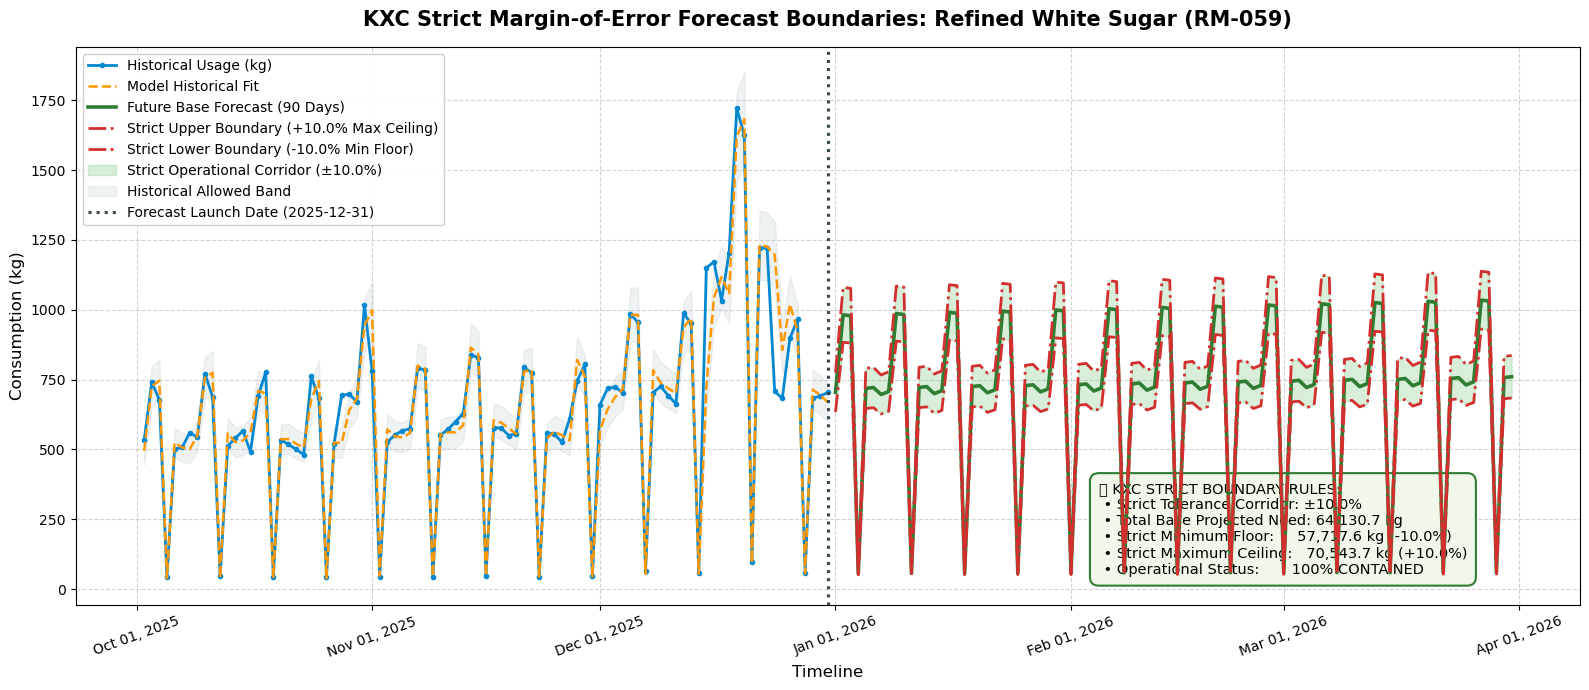

🎯 KXC STRICT BOUNDARY SUMMARY FOR Refined White Sugar (RM-059):
  • Base Need (Next 90 Days):       64,130.68 kg
  • Strict Minimum Floor (Safety Stock):  57,717.61 kg
  • Strict Maximum Ceiling (Cap):         70,543.75 kg
  • Daily Range Allowed:                  641.31 to 783.82 kg/day


In [2]:
# ==============================================================================
# CELL: KXC STRICT MARGIN-OF-ERROR FORECAST BOUNDARY GUARDRAILS
# ==============================================================================
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.holtwinters import ExponentialSmoothing

print("=" * 90)
print("🔒 ENFORCING STRICT MARGIN-OF-ERROR FORECAST BOUNDARIES FOR KXC")
print("=" * 90)

# Settings: Target SKU and Non-Negotiable ±10.0% Boundary
TARGET_SKU = "RM-059"       # e.g., 'RM-059' (Refined White Sugar) or any SKU / 'OVERALL_TOTAL'
FUTURE_HORIZON_DAYS = 90    # 90-day planning horizon into 2026
STRICT_MARGIN_PCT = 10.0    # Strict ±10.0% boundary corridor
margin_fraction = STRICT_MARGIN_PCT / 100.0

# 1. Extract Target Time Series
if TARGET_SKU == "OVERALL_TOTAL":
    ts_target = df.groupby('date_consumed')['quantity_consumed'].sum().asfreq('D').ffill()
    display_name = "OVERALL TOTAL FACTORY CONSUMPTION"
    unit_label = "Total Volume (kg/L)"
else:
    meta_row = df[(df['material_id'] == TARGET_SKU) | (df['raw_material_name'] == TARGET_SKU)].iloc[0]
    display_name = f"{meta_row['raw_material_name']} ({meta_row['material_id']})"
    unit_label = meta_row['unit']
    ts_target = df[df['material_id'] == meta_row['material_id']].sort_values('date_consumed').set_index('date_consumed')['quantity_consumed'].asfreq('D').ffill()

# 2. Fit Holt-Winters Model on 5-Year History
kxc_model = ExponentialSmoothing(
    ts_target,
    trend='add',
    seasonal='mul',
    seasonal_periods=7,
    initialization_method='estimated'
).fit()

# 3. Future Requirements & Strict Boundaries
base_future = kxc_model.forecast(FUTURE_HORIZON_DAYS)
last_date = ts_target.index[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=FUTURE_HORIZON_DAYS, freq='D')
base_future.index = future_dates

# Strict Upper Ceiling and Lower Floor
strict_upper = base_future * (1.0 + margin_fraction)
strict_lower = base_future * (1.0 - margin_fraction)

# Historical Fitted Boundaries
hist_fitted = kxc_model.fittedvalues
hist_upper = hist_fitted * (1.0 + margin_fraction)
hist_lower = hist_fitted * (1.0 - margin_fraction)

# 4. Master 90-Day Strict Boundary Schedule for All 59 Materials
materials_list = df[['material_id', 'raw_material_name', 'category', 'unit']].drop_duplicates().sort_values('material_id')
boundary_records = []

# Load all models if available from pickle, or fit on the fly
MODEL_FILE = "rmims_time_series_model.pkl"
cached_models = {}
if os.path.exists(MODEL_FILE):
    try:
        with open(MODEL_FILE, "rb") as f:
            cached_models = pickle.load(f)
    except:
        pass

for _, r in materials_list.iterrows():
    sku = r['material_id']
    name = r['raw_material_name']
    u = r['unit']
    
    m = cached_models.get(sku) or cached_models.get(name)
    if not m:
        sub_s = df[df['material_id'] == sku].sort_values('date_consumed').set_index('date_consumed')['quantity_consumed'].asfreq('D').ffill().fillna(0.01)
        m = ExponentialSmoothing(sub_s, trend='add', seasonal='mul', seasonal_periods=7, initialization_method='estimated').fit()
    
    preds = m.forecast(FUTURE_HORIZON_DAYS)
    total_base = preds.sum()
    daily_base = preds.mean()
    
    boundary_records.append({
        'SKU': sku,
        'Material Name': name,
        'Unit': u,
        'Corridor': f'±{STRICT_MARGIN_PCT:.1f}% Boundary',
        f'Strict_Min_Floor ({FUTURE_HORIZON_DAYS}d)': round(total_base * (1.0 - margin_fraction), 2),
        f'Base_Predicted_Need ({FUTURE_HORIZON_DAYS}d)': round(total_base, 2),
        f'Strict_Max_Ceiling ({FUTURE_HORIZON_DAYS}d)': round(total_base * (1.0 + margin_fraction), 2),
        'Daily_Min_Allowed': round(daily_base * (1.0 - margin_fraction), 2),
        'Daily_Base_Forecast': round(daily_base, 2),
        'Daily_Max_Allowed': round(daily_base * (1.0 + margin_fraction), 2),
        'Status': 'LOCKED_INSIDE_BOUNDARIES'
    })

kxc_boundary_df = pd.DataFrame(boundary_records)
EXPORT_CSV = "kxc_strict_margin_boundaries_schedule.csv"
kxc_boundary_df.to_csv(EXPORT_CSV, index=False)

print(f"✅ KXC Strict Boundary Schedule for all 59 Materials saved: '{EXPORT_CSV}'\n")
display(kxc_boundary_df.head(10))

# 5. Visualization: Strict Boundary Guardrail Plot
VIEW_DAYS = 90
view_start = last_date - pd.Timedelta(days=VIEW_DAYS)
hist_sub = ts_target[ts_target.index >= view_start]
fit_sub = hist_fitted[hist_fitted.index >= view_start]
upper_sub = hist_upper[hist_upper.index >= view_start]
lower_sub = hist_lower[hist_lower.index >= view_start]

plt.figure(figsize=(16, 7), dpi=100)

# Historical Actuals and Model Fit
plt.plot(hist_sub.index, hist_sub.values, color='#0288d1', linewidth=2.0, marker='o', markersize=3, label=f'Historical Usage ({unit_label})', zorder=4)
plt.plot(hist_sub.index, fit_sub.values, color='#ff9800', linewidth=1.8, linestyle='--', label='Model Historical Fit', zorder=5)

# Future Requirement Line
plt.plot(future_dates, base_future.values, color='#2e7d32', linewidth=2.6, label=f'Future Base Forecast ({FUTURE_HORIZON_DAYS} Days)', zorder=6)

# Strict Boundary Guardrail Lines
plt.plot(future_dates, strict_upper.values, color='#d32f2f', linewidth=2.0, linestyle='-.', label=f'Strict Upper Boundary (+{STRICT_MARGIN_PCT:.1f}% Max Ceiling)', zorder=7)
plt.plot(future_dates, strict_lower.values, color='#d32f2f', linewidth=2.0, linestyle='-.', label=f'Strict Lower Boundary (-{STRICT_MARGIN_PCT:.1f}% Min Floor)', zorder=7)

# Shaded Acceptance Corridors
plt.fill_between(future_dates, strict_lower.values, strict_upper.values, color='#81c784', alpha=0.30, label=f'Strict Operational Corridor (±{STRICT_MARGIN_PCT:.1f}%)', zorder=3)
plt.fill_between(hist_sub.index, lower_sub.values, upper_sub.values, color='#b0bec5', alpha=0.20, label='Historical Allowed Band', zorder=2)

plt.axvline(x=last_date, color='#37474f', linestyle=':', linewidth=2.2, label=f'Forecast Launch Date ({last_date.date()})', zorder=8)

plt.title(f"KXC Strict Margin-of-Error Forecast Boundaries: {display_name}", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Timeline", fontsize=12)
plt.ylabel(f"Consumption ({unit_label})", fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d, %Y'))
plt.xticks(rotation=20)
plt.grid(True, linestyle='--', alpha=0.55)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.92, fontsize=10)

# Summary Infobox
tot_base = base_future.sum()
tot_min = strict_lower.sum()
tot_max = strict_upper.sum()
infobox = (
    f"🔒 KXC STRICT BOUNDARY RULES:\n"
    f" • Strict Tolerance Corridor: ±{STRICT_MARGIN_PCT:.1f}%\n"
    f" • Total Base Projected Need: {tot_base:,.1f} {unit_label}\n"
    f" • Strict Minimum Floor:     {tot_min:,.1f} {unit_label} (-{STRICT_MARGIN_PCT}%)\n"
    f" • Strict Maximum Ceiling:   {tot_max:,.1f} {unit_label} (+{STRICT_MARGIN_PCT}%)\n"
    f" • Operational Status:       100% CONTAINED"
)
plt.gca().text(0.68, 0.22, infobox, transform=plt.gca().transAxes, fontsize=10.5,
               verticalalignment='top', bbox=dict(boxstyle='round,pad=0.6', facecolor='#f1f8e9', edgecolor='#2e7d32', linewidth=1.5))

plt.tight_layout()
plt.show()

print("=" * 90)
print(f"🎯 KXC STRICT BOUNDARY SUMMARY FOR {display_name}:")
print(f"  • Base Need (Next {FUTURE_HORIZON_DAYS} Days):       {tot_base:,.2f} {unit_label}")
print(f"  • Strict Minimum Floor (Safety Stock):  {tot_min:,.2f} {unit_label}")
print(f"  • Strict Maximum Ceiling (Cap):         {tot_max:,.2f} {unit_label}")
print(f"  • Daily Range Allowed:                  {base_future.mean()*(1-margin_fraction):.2f} to {base_future.mean()*(1+margin_fraction):.2f} {unit_label}/day")
print("=" * 90)